In [ ]:
# !git clone https://github.com/laboratorioAI/DTW_ANN_EPN_Python.git


Cloning into 'DTW_ANN_EPN_Python'...
remote: Enumerating objects: 64, done.
remote: Counting objects: 100% (64/64), done.
remote: Compressing objects: 100% (56/56), done.
remote: Total 64 (delta 8), reused 64 (delta 8), pack-reused 0
Receiving objects: 100% (64/64), 30.84 MiB | 19.02 MiB/s, done.
Resolving deltas: 100% (8/8), done.


In [ ]:
# ## to download testingjson dataset from the above clone

# import shutil
# from google.colab import files

# # Specify the folder you want to download
# folder_to_download = '/content/DTW_ANN_EPN_Python/testingJSON'  # Replace with your folder path

# # Create a zip archive of the folder
# shutil.make_archive('testingJSON', 'zip', folder_to_download)

# # Download the zip file
# files.download('testingJSON.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ## to download the trainingjson dataset from the above clone

# import shutil
# from google.colab import files

# # Specify the folder you want to download
# folder_to_download = '/content/DTW_ANN_EPN_Python/trainingJSON'  # Replace with your folder path

# # Create a zip archive of the folder
# shutil.make_archive('trainingJSON', 'zip', folder_to_download)

# # Download the zip file
# files.download('trainingJSON.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
## pre processing.py

#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Wed Jul 22 22:33:37 2020

@author: aguasharo
"""

import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
import math


def butter_lowpass_filter(data, fs, order):
    # Get the filter coefficients
    b, a = signal.butter(order, fs, 'low', analog = False)
    y = signal.filtfilt(b, a, data)
    return y



def preProcessEMGSegment(EMGsegment_in):
    # This function to apply a filter
    EMG = max(EMGsegment_in)

    if EMG > 1:
        EMGnormalized = EMGsegment_in/128
    else:
        EMGnormalized = EMGsegment_in

    EMGrectified = abs(EMGnormalized)
    EMGsegment_out = butter_lowpass_filter(EMGrectified, 0.1, 5)
    return EMGsegment_out



def detectMuscleActivity(emg_sum):
    # This function segments in a EMG the region corresponding to a muscle
    # contraction. The indices idxStart and idxEnd correspond to the begining
    # and the end of such a region

    # Sampling frequency of the EMG
    fs = 200
    minWindowLength_Segmentation =  100 # Minimum length of the segmented region
    hammingWdw_Length = np.hamming(25) # Window length
    numSamples_lapBetweenWdws = 10 # Overlap between 2 consecutive windows
    threshForSum_AlongFreqInSpec = 0.86

    [s, f, t, im] = plt.specgram(emg_sum, NFFT = 25, Fs = fs, window = hammingWdw_Length, noverlap = numSamples_lapBetweenWdws, mode = 'magnitude', pad_to = 50)

    # Summing the spectrogram along the frequencies
    sumAlongFreq = [sum(x) for x in zip(*s)]

    greaterThanThresh = []
    # Thresholding the sum sumAlongFreq
    for item in sumAlongFreq:
        if item >= threshForSum_AlongFreqInSpec:
            greaterThanThresh.append(1)
        else:
            greaterThanThresh.append(0)

    greaterThanThresh.insert(0,0)
    greaterThanThresh.append(0)
    diffGreaterThanThresh = abs(np.diff(greaterThanThresh))

    if diffGreaterThanThresh[-1] == 1:
        diffGreaterThanThresh[-2] = 1;

    x = diffGreaterThanThresh[0:-1];
    findNumber = lambda x, xs: [i for (y, i) in zip(xs, range(len(xs))) if x == y]
    idxNonZero = findNumber(1,x)
    numIdxNonZero = len(idxNonZero)
    idx_Samples = np.floor(fs*t)
    # Finding the indices of the start and the end of a muscle contraction
    if numIdxNonZero == 0:
        idx_Start = 1
        idx_End = len(emg_sum)
    elif numIdxNonZero == 1:
        idx_Start = idx_Samples[idxNonZero]
        idx_End = len(emg_sum)
    else:
        idx_Start = idx_Samples[idxNonZero[0]]
        idx_End = idx_Samples[idxNonZero[-1]-1]
    # Adding a head and a tail to the segmentation
    numExtraSamples = 25
    idx_Start = max(1,idx_Start - numExtraSamples)
    idx_End = min(len(emg_sum), idx_End + numExtraSamples)

    if (idx_End - idx_Start) < minWindowLength_Segmentation:
        idx_Start = 1
        idx_End = len(emg_sum)


    return int(idx_Start), int(idx_End)


def EMG_segment(train_filtered_X):
    # This function return a segment with corresponding to a muscle
    # contraction

    df_sum  = train_filtered_X.sum(axis=1)
    idx_Start, idx_End = detectMuscleActivity(df_sum)
    df_seg = train_filtered_X.iloc[idx_Start:idx_End]

    return df_seg

In [3]:
!pip install fastdtw

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.4/133.4 kB 3.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for fastdtw: filename=fastdtw-0.3.4-cp311-cp311-linux_x86_64.whl size=542087 sha256=0117e28220c71211ec2095d505e0cfb1b5b476de2abc5561e54ce3d3bfd84906
  Stored in directory: /root/.cache/pip/wheels/5c/8a/f6/fd3df9a9714677410a5ccbf3ca519e66db4a54a1c46ea95332
Successfully built fastdtw


In [4]:
## feature extraction.py

#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Wed Jul 22 23:22:24 2020

@author: aguasharo
"""

import numpy as np
import pandas as pd
from fastdtw import fastdtw
from scipy.spatial.distance import euclidean


def findCentersClass(emg_filtered):
    # This function returns a set of time series called centers. The ith
    # time series of centers, centers{i}, is the center of the cluster of time
    # series from the set timeSeries that belong to the ith class. For finding
    # the center of each class, the DTW distance is used.

    distances = []
    sample = 25
    column = np.arange(0,sample)
    mtx_distances = pd.DataFrame(columns = column)
    mtx_distances = mtx_distances.fillna(0) # with 0s rather than NaNs


    for sample_i in emg_filtered:
        for sample_j in emg_filtered:
            dist, dummy = fastdtw(sample_i, sample_j, dist = euclidean)
            distances.append(dist)

        df_length = len(mtx_distances)
        mtx_distances.loc[df_length] = distances
        distances= []
    vector_dist = mtx_distances.sum(axis=0)
    idx = vector_dist.idxmin()
    center_idx = emg_filtered[int(idx)]

    return center_idx


def featureExtractionf(emg_filtered, centers):
    # This function computes a feature vector for each element from the set
    # timeSeries. The dimension of this feature vector depends on the number of
    # time series of the set centers. The value of the jth feature of the ith
    # vector in dataX corresponds to the DTW distance between the signals
    # timeSeries{i} and centers{j}.

    dist_features = []

    column = np.arange(0,len(centers))
    dataX = pd.DataFrame(columns = column)
    dataX = dataX.fillna(0)

    for rep in emg_filtered:
        for middle in centers:
            dist, dummy = fastdtw(rep, middle, dist = euclidean)
            dist_features.append(dist)

        dataX_length = len(dataX)
        dataX.loc[dataX_length] = dist_features
        dist_features = []

    return dataX


def preProcessFeatureVector(dataX_in):
    # This function preprocess each feature vector of the set dataX_in. Each
    # row of dataX_in is a fetaure vector and each column is a featur
    num_gestures = 6
    dataX_mean = dataX_in.mean(axis = 1)
    dataX_std = dataX_in.std(axis = 1)
    dataX_mean6 =  pd.concat([dataX_mean]*num_gestures, axis = 1)
    dataX_std6 =  pd.concat([dataX_std]*num_gestures, axis = 1)
    dataX6 = (dataX_in - dataX_mean6)/dataX_std6

    return dataX6


In [ ]:
# ## post processing.py

# #!/usr/bin/env python3
# # -*- coding: utf-8 -*-
# """
# Created on Thu Jul 23 00:03:12 2020

# @author: aguasharo
# """



# def majorite_vote(data, before, after):
#     # This function is used to apply pos-processing based on majority vote

#     votes =[0,0,0,0,0,0]
#     class_maj = []

#     for j in range(0,len(data)):
#         wind_mv = data[max(0,(j-before)):min(len(data),(j+after))]

#         for k in range(0, 6):
#             a = [1 if i == k+1 else 0 for i in wind_mv]
#             votes[k] = sum(a)

#         findNumber = lambda x, xs: [i for (y, i) in zip(xs, range(len(xs))) if x == y]
#         idx_label = findNumber(max(votes),votes)
#         class_maj.append( idx_label[0] + 1)


#     return class_maj


# def unique(list1):
#     # insert the list to the set
#     list_set = set(list1)
#     # convert the set to the list
#     unique_list = (list(list_set))

#     return unique_list


In [5]:
## read dataset.py

#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Wed Jul 22 23:54:28 2020

@author: aguasharo
"""


def get_y_train(train_samples):
    # Changes a gesture into a code
    y_train = []

    for sample in train_samples:

        y = train_samples[sample]['gestureName']

        if y == 'noGesture':
            code = 1

        elif y == 'fist':
            code = 2

        elif y == 'waveIn':
            code = 3

        elif y == 'waveOut':
            code = 4

        elif y == 'open':
            code = 5

        elif y == 'pinch':
            code = 6

        y_train.append(code)


    return y_train


# def code2gesture(code):
#     # This function returns the gesture name from code

#     if code == 1:
#         label = 'noGesture'

#     elif code == 2:
#         label = 'fist'

#     elif code == 3:
#         label = 'waveIn'

#     elif code == 4:
#         label = 'waveOut'

#     elif code == 5:
#         label = 'open'

#     elif code == 6:
#         label = 'pinch'


#     return label


# def code2gesture_labels(vector_labels_prev):
#     # This function returns a prediction vector with gesture names

#     v2 = []

#     for window in vector_labels_prev:

#         vec_prev = code2gesture(window)
#         v2.append(vec_prev)

#     return v2

In [ ]:
# ## classificationEMG.py

# #!/usr/bin/env python3
# # -*- coding: utf-8 -*-
# """
# Created on Thu Jul 23 00:07:43 2020

# @author: aguasharo
# """


# # from preProcessing import *
# # from featureExtraction import *
# # from postProcessing import *
# import pandas as pd
# import numpy as np
# import time


# def classifyEMG_SegmentationNN(dataX_test, centers, model):
#     # This function applies a hand gesture recognition model based on artificial
#     # feed-forward neural networks and automatic feature extraction to a set of
#     # EMGs conatined in the set test_X. The actual label of each EMG in test_X
#     # is in the set test_Y. The structure nnModel contains the trained neural
#     # network

#     window_length = 600
#     stride_length = 30
#     emg_length = len(dataX_test)
#     predLabel_seq = []
#     vecTime = []
#     timeSeq = []


#     count = 0
#     while True:
#         start_point = stride_length*count + 1
#         end_point = start_point + window_length - 1

#         if end_point > emg_length:
#             break

#         tStart = time.time()
#         window_emg = dataX_test.iloc[start_point:end_point]
#         filt_window_emg = window_emg.apply(preProcessEMGSegment)
#         window_sum  = filt_window_emg.sum(axis=1)
#         idx_start, idx_end = detectMuscleActivity(window_sum)
#         t_acq = time.time()-tStart

#         if (idx_start != 1) & (idx_end != len(window_emg)) & ((idx_end - idx_start) > 85):

#             tStart = time.time()

#             filt_window_emg1 = window_emg.apply(preProcessEMGSegment)
#             window_emg1 = filt_window_emg1.iloc[idx_start:idx_end]


#             t_filt = time.time() - tStart

#             tStart = time.time()
#             featVector = featureExtractionf([window_emg1], centers)
#             featVectorP = preProcessFeatureVector(featVector)
#             t_featExtra =  time.time() - tStart

#             tStart = time.time()
#             # x = model.predict_proba(featVectorP).tolist()


#             # Assuming model is your Keras Sequential model and featVectorP is your input data
#             predictions = model.predict(featVectorP)
#             # Normalize the predicted probabilities
#             probabilities = np.exp(predictions) / np.sum(np.exp(predictions), axis=1, keepdims=True)
#             # Convert to list
#             probabilities_list = probabilities.tolist()
#             x=probabilities_list

#             probNN = x[0]
#             max_probNN = max(probNN)
#             predicted_labelNN = probNN.index(max_probNN) + 1
#             t_classiNN = time.time() - tStart

#             tStart = time.time()
#             if max_probNN <= 0.5:
#                 predicted_labelNN = 1
#             t_threshNN = time.time() - tStart
#             #print(predicted_labelNN)

#         else:

#             t_filt = 0
#             t_featExtra = 0
#             t_classiNN = 0
#             t_threshNN = 0
#             predicted_labelNN = 1
#             #print('1')


#         count = count + 1
#         predLabel_seq.append(predicted_labelNN)
#         vecTime.append(start_point+(window_length/2)+50)
#         timeSeq.append(t_acq + t_filt + t_featExtra + t_classiNN + t_threshNN)

#     pred_seq = majorite_vote(predLabel_seq, 5, 5)

#     return  pred_seq, vecTime, timeSeq




# def post_ProcessLabels(predicted_Seq):
#     # This function post-processes the sequence of labels returned by a
#     # classifier. Each row of predictedSeq is a sequence of
#     # labels predicted by a different classifier for the jth example belonging
#     # to the ith actual class.

#     time_post = []
#     predictions = predicted_Seq.copy()
#     predictions[0] = 1
#     postProcessed_Labels = predictions.copy()

#     for i in range(1,len(predictions)):

#         tStart = time.time()

#         if predictions[i] == predictions[i-1]:
#             cond = 1
#         else:
#             cond = 0

#         postProcessed_Labels[i] =  (1 * cond) + (predictions[i]* (1 - cond))
#         t_post = time.time() - tStart
#         time_post.append(t_post)

#     time_post.insert(0,time_post[0])
#     uniqueLabels = unique(postProcessed_Labels)

#     an_iterator = filter(lambda number: number != 1, uniqueLabels)
#     uniqueLabelsWithoutRest = list(an_iterator)

#     if not uniqueLabelsWithoutRest:

#         finalLabel = 1

#     else:

#         if len(uniqueLabelsWithoutRest) > 1:
#             finalLabel = uniqueLabelsWithoutRest[0]

#         else:
#             finalLabel = uniqueLabelsWithoutRest[0]


#     return finalLabel, time_post


In [6]:
## recognition functions.py


#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Thu Aug 27 23:57:41 2020

@author: aguasharo
"""


# from readDataset import *
# from preProcessing import *
# from featureExtraction import *
# from classificationEMG import *



from sklearn.manifold import TSNE
import seaborn as sns


import keras
from keras.models import Sequential
from keras.layers import Dense
from sklearn.preprocessing import LabelEncoder
# from keras.utils import np_utils
from keras.utils import to_categorical
from keras.optimizers import Adam, SGD


from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score


from sklearn.preprocessing import StandardScaler

import collections
from collections import Counter



def get_x_train(user,sample):
    # This function reads the time series(x) of the user (Training Sample)
    train_samples = user['trainingSamples']
    x = (train_samples[sample]['emg'])
    # Divide to 128 for having a signal between -1 and 1
    df = pd.DataFrame.from_dict(x) / 128
    # Apply filter
    train_filtered_X = df.apply(preProcessEMGSegment)
    # Segment the filtered EMG signal
    train_segment_X = EMG_segment(train_filtered_X)

    return train_segment_X



# def get_x_test(user,sample):
#     # This function reads the time series(x) of the user (Testing Sample)
#     test_samples = user['testingSamples']
#     x = (test_samples[sample]['emg'])
#     df = pd.DataFrame.from_dict(x) / 128

#     return df


def get_x_test(user,sample):
    # This function reads the time series(x) of the user (Training Sample)
    train_samples = user['testingSamples']
    x = (train_samples[sample]['emg'])
    # Divide to 128 for having a signal between -1 and 1
    df = pd.DataFrame.from_dict(x) / 128
    # Apply filter
    train_filtered_X = df.apply(preProcessEMGSegment)
    # Segment the filtered EMG signal
    train_segment_X = EMG_segment(train_filtered_X)

    return train_segment_X



def decode_targets(y_train):
    # Encode targets to train the Neural Network
    encoder = LabelEncoder()
    encoder.fit(y_train)
    encoded_Y = encoder.transform(y_train)
    # target = np_utils.to_categorical(encoded_Y)
    target = to_categorical(encoded_Y)

    return target


# def get_xy_val(X_train, targets):

#     # Get validation data to train Neural Network
#     data_val = X_train.copy()
#     data_val['6'] = targets

#     xy_val = data_val.sample(frac=1).reset_index(drop=True)


#     X_val = xy_val.iloc[:,0:6]
#     y_val = decode_targets(xy_val['6'])


#     return X_val, y_val



def bestCenter_Class(train_segment_X):

    # This function returns a set of time series called centers
    # for each gesture class

    g1 = train_segment_X[0:25]
    g2 = train_segment_X[25:50]
    g3 = train_segment_X[50:75]
    g4 = train_segment_X[75:100]
    g5 = train_segment_X[100:125]
    g6 = train_segment_X[125:150]

    gen = [g1, g2, g3, g4, g5 ,g6]

    c = [findCentersClass(g) for g in gen]

    return c



def getFeatureExtraction(emg_filtered, centers):

    features = featureExtractionf(emg_filtered, centers)
    dataX = preProcessFeatureVector(features)

    return dataX



# def trainFeedForwardNetwork(X_train,y_train, X_test, y_test):
#     # This function trains an  artificial feed-forward neural networks
#     # Cost lost: categorical cross entropy
#     # Hidden Layer: Tanh
#     # Output Layer: softmax

#     classifier = Sequential()

#     classifier.add(Dense(units = 6, kernel_initializer = 'uniform', activation = None, input_dim = 6))
#     classifier.add(Dense(units = 6, kernel_initializer = 'uniform', activation = 'tanh'))
#     classifier.add(Dense(units = 6, kernel_initializer = 'uniform', activation = 'softmax'))
#     classifier.compile(optimizer = 'adam', loss = 'categorical_crossentropy', metrics = ['accuracy'])
#     classifier.fit(X_train, y_train, batch_size = 150, epochs = 1500, validation_data = (X_test, y_test), verbose = 0 )

#     return classifier




# def testing_prediction(user,sample,centers,estimator):
#     test_RawX = get_x_test(user,sample)
#     [predictedSeq, vec_time, time_seq]= classifyEMG_SegmentationNN(test_RawX, centers, estimator)
#     predicted_label, t_post = post_ProcessLabels(predictedSeq)

#     # Computing the time of processing
#     estimatedTime =  [sum(x) for x in zip(time_seq, t_post)]


#     return predicted_label, predictedSeq, vec_time, estimatedTime



# def recognition_results(results):
#      # This function save the responses of each user into a dictionary

#     d = collections.defaultdict(dict)

#     for i in range(0,150):

#         d['idx_%s' %i]['class'] = code2gesture(results[i][0])
#         d['idx_%s' %i]['vectorOfLabels'] = code2gesture_labels(results[i][1])
#         d['idx_%s' %i]['vectorOfTimePoints'] = results[i][2]
#         d['idx_%s' %i]['vectorOfProcessingTime']= results[i][3]

#     return d


In [ ]:
# ## recognition model.py


# #!/usr/bin/env python3
# # -*- coding: utf-8 -*-
# """
# Created on Thu Aug 27 23:59:24 2020

# @author: aguasharo
# """

# # from recognitionFunctions import *


# class RecognitionModel_train:

#     num_gestures = 6

#     def __init__(self,version,user):
#         self.user = user
#         self.version = version


#     def preProcessingData(self):
#         sample_type = self.version+'Samples'
#         # Reading the training samples
#         train_samples = self.user[sample_type]
#         # Preprocessing
#         train_segment_X = [get_x_train(self.user,sample) for sample in train_samples]

#         return train_segment_X

#     def featureExtraction(self, train_data):
#         # Finding the EMG that is the center of each class
#         centers = bestCenter_Class(train_data)
#         # Feature extraction by computing the DTW distance between each training
#         # example and the center of each cluster
#         # Preprocessing the feature vectors
#         X_train = getFeatureExtraction(train_data, centers)

#         return X_train, centers


#     def trainSoftmaxNN(self):
#         sample_type = self.version+'Samples'
#         # Reading the training samples
#         train_samples = self.user[sample_type]
#         # Training the feed-forward NN
#         y_train = decode_targets(get_y_train(train_samples))
#         # X_val, y_val = get_xy_val(X_train, get_y_train(train_samples))
#         # estimator = trainFeedForwardNetwork(X_train, y_train, X_val, y_val)

#         # return estimator
#         return y_train


#     # def trainSoftmaxNN(self, X_train):
#     #     sample_type = self.version+'Samples'
#     #     # Reading the training samples
#     #     train_samples = self.user[sample_type]
#     #     # Training the feed-forward NN
#     #     y_train = decode_targets(get_y_train(train_samples))
#     #     # X_val, y_val = get_xy_val(X_train, get_y_train(train_samples))
#     #     # estimator = trainFeedForwardNetwork(X_train, y_train, X_val, y_val)

#     #     # return estimator
#     #     return y_train


#     # def classifyGestures(self,version, estimator, centers) :

#     #     sample_type = self.version+'Samples'
#     #     # Reading the testing samples
#     #     test_samples = self.user[sample_type]
#     #     # Concatenating the predictions of all the users for computing the
#     #     # errors
#     #     response = ([testing_prediction(self.user, sample, centers, estimator) for sample in test_samples])

#     #     results = recognition_results(response)

#     #     return results


In [7]:
## recognition model.py


#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Thu Aug 27 23:59:24 2020

@author: aguasharo
"""

# from recognitionFunctions import *


class RecognitionModel_test:

    num_gestures = 6

    def __init__(self,version,user):
        self.user = user
        self.version = version


    def preProcessingData(self):
        sample_type = self.version+'Samples'
        # Reading the training samples
        train_samples = self.user[sample_type]
        # Preprocessing
        train_segment_X = [get_x_test(self.user,sample) for sample in train_samples]

        return train_segment_X

    def featureExtraction(self, train_data):
        # Finding the EMG that is the center of each class
        centers = bestCenter_Class(train_data)
        # Feature extraction by computing the DTW distance between each training
        # example and the center of each cluster
        # Preprocessing the feature vectors
        X_train = getFeatureExtraction(train_data, centers)

        return X_train, centers


    def trainSoftmaxNN(self):
        sample_type = self.version+'Samples'
        # Reading the training samples
        train_samples = self.user[sample_type]
        # Training the feed-forward NN
        y_train = decode_targets(get_y_train(train_samples))
        # X_val, y_val = get_xy_val(X_train, get_y_train(train_samples))
        # estimator = trainFeedForwardNetwork(X_train, y_train, X_val, y_val)

        # return estimator
        return y_train


    # def trainSoftmaxNN(self, X_train):
    #     sample_type = self.version+'Samples'
    #     # Reading the training samples
    #     train_samples = self.user[sample_type]
    #     # Training the feed-forward NN
    #     y_train = decode_targets(get_y_train(train_samples))
    #     # X_val, y_val = get_xy_val(X_train, get_y_train(train_samples))
    #     # estimator = trainFeedForwardNetwork(X_train, y_train, X_val, y_val)

    #     # return estimator
    #     return y_train


    # def classifyGestures(self,version, estimator, centers) :

    #     sample_type = self.version+'Samples'
    #     # Reading the testing samples
    #     test_samples = self.user[sample_type]
    #     # Concatenating the predictions of all the users for computing the
    #     # errors
    #     response = ([testing_prediction(self.user, sample, centers, estimator) for sample in test_samples])

    #     results = recognition_results(response)

    #     return results


In [8]:
## main.py

#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Wed Jul 22 22:37:27 2020

@author: aguasharo
"""

from __future__ import print_function

import json
import os
import collections

# from RecognitionModel import RecognitionModel





#%% Read user data
response = collections.defaultdict(dict)
num_gestures = 6
# folderData = 'testingJSON'
# folderData = '/home/ranirupa/training_21'
folderData = '/content/drive/MyDrive/trainingJson'

cont = 0
entries = os.listdir(folderData)
num_users = len(entries)




In [ ]:
# import torch

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### Feature extraction of training samples for model training

In [ ]:
# from sklearn.model_selection import train_test_split

# # Initialize lists to store data for all users
# all_X_train = []
# all_y_train = []

# # Read and process data for each user
# for entry in entries:
#     file_selected = os.path.join(folderData, entry, f"{entry}.json")
#     print('num of users in the dataset used : ', len(entries))
#     print('file used now is', file_selected)


#     with open(file_selected) as file:
#         # Read user data
#         user = json.load(file)
#         name_user = user['userInfo']['name']

#         # Create a RecognitionModel instance for the current user
#         currentUser = RecognitionModel_train('training', user)

#         print('current user is ', currentUser)

#         # Preprocess the data for the current user
#         train_segment_X = currentUser.preProcessingData()

#         # Extract features and labels
#         X_train_user, centers = currentUser.featureExtraction(train_segment_X)
#         y_train_user = currentUser.trainSoftmaxNN(X_train_user)

#         # Ensure X_train_user and y_train_user are numpy arrays
#         if isinstance(X_train_user, pd.DataFrame):
#             X_train_user = X_train_user.values  # Convert DataFrame to numpy array
#         if isinstance(y_train_user, pd.DataFrame):
#             y_train_user = y_train_user.values  # Convert DataFrame to numpy array

#         # Check shapes
#         print(f"User: {name_user}, X_train_user shape: {X_train_user.shape}, y_train_user shape: {y_train_user.shape}")

#         # Append the current user's data to the full dataset lists
#         all_X_train.append(X_train_user)
#         all_y_train.append(y_train_user)

# # Convert lists of arrays to single numpy arrays
# all_X_train = np.vstack(all_X_train)  # Stack arrays vertically
# all_y_train = np.vstack(all_y_train)  # Stack arrays vertically

# # Check total shapes
# print(f"Total X shape: {all_X_train.shape}, Total y shape: {all_y_train.shape}")

# # Ensure that the lengths of all_X_train and all_y_train match
# if all_X_train.shape[0] != all_y_train.shape[0]:
#     print(f"Warning: Mismatch in lengths! X: {all_X_train.shape[0]}, y: {all_y_train.shape[0]}")

# # Split the combined data into training and testing sets
# X_train_split, X_test_split, y_train_split, y_test_split = train_test_split(all_X_train, all_y_train, test_size=0.2, random_state=42)


## working directly on muscle segments without dtw of training samples to check on rnn

In [ ]:
# from tensorflow.keras.preprocessing.sequence import pad_sequences
# import numpy as np
# import json
# import os
# from sklearn.model_selection import train_test_split

# # Initialize lists to store data for all users
# all_X_train = []
# all_y_train = []
# all_X_train_prep_only = []
# all_X_train_prep_only_padded = []

# # Variable to track the maximum length of train_segment_X across all users
# max_length = 0

# # Read and process data for each user
# for entry in entries:
#     file_selected = os.path.join(folderData, entry, f"{entry}.json")
#     print('Number of users in the dataset:', len(entries))
#     print('Processing file:', file_selected)

#     with open(file_selected) as file:
#         # Read user data
#         user = json.load(file)
#         name_user = user['userInfo']['name']

#         # Create a RecognitionModel instance for the current user
#         currentUser = RecognitionModel_train('training', user)

#         print('current user is ', currentUser)


#         # Preprocess the data for the current user
#         train_segment_X = currentUser.preProcessingData()
#         # X_train_user, centers = currentUser.featureExtraction(train_segment_X)

#         if isinstance(train_segment_X, list):
#             print(f"Length of train_segment_X for user {name_user}: {len(train_segment_X)}")

#             # Find the maximum length of sequences across all users
#             max_seq_length = max(max_length, max(len(seq) for seq in train_segment_X))
#             max_length = max_seq_length  # Update the global max length

#             # Pad the sequences to the maximum length
#             train_segment_X = pad_sequences(train_segment_X, maxlen=max_length, padding='post', dtype='float32')

#             print(f"Padded train_segment_X shape for user {name_user}: {train_segment_X.shape}")
#         else:
#             print(f"Shape of train_segment_X for user {name_user}: {train_segment_X.shape}")

#         # Extract features and labels
#         # y_train_user = currentUser.trainSoftmaxNN(X_train_user)
#         y_train_user = currentUser.trainSoftmaxNN()


#         if isinstance(y_train_user, pd.DataFrame):
#             y_train_user = y_train_user.values  # Convert DataFrame to numpy array
#         if isinstance(train_segment_X, pd.DataFrame):
#             train_segment_X = train_segment_X.values  # Convert DataFrame to numpy array

#         # Append the current user's data to the full dataset lists
#         all_y_train.append(y_train_user)
#         all_X_train_prep_only.append(train_segment_X)

# # Now, pad all data to the consistent length
# for user_data in all_X_train_prep_only:
#     # Pad the sequences to the maximum length
#     padded_user_data = pad_sequences(user_data, maxlen=max_length, padding='post', dtype='float32')
#     all_X_train_prep_only_padded.append(padded_user_data)

#     # Print the shape of the padded data to verify padding worked
#     print(f"Padded data shape for user: {padded_user_data.shape}")

# # Convert the list of padded arrays into a single numpy array
# all_X_train_prep_only_padded = np.vstack(all_X_train_prep_only_padded)

# # Check the shape after padding
# print(f"Total padded train_segment_X shape: {all_X_train_prep_only_padded.shape}")

# # Convert lists of arrays to single numpy arrays
# all_y_train = np.vstack(all_y_train)  # Stack arrays vertically

# # Ensure that the lengths of all_X_train_prep_only_padded and all_y_train match
# if all_X_train_prep_only_padded.shape[0] != all_y_train.shape[0]:
#     print(f"Warning: Mismatch in lengths! X_prep_only: {all_X_train_prep_only_padded.shape[0]}, y: {all_y_train.shape[0]}")

# # Split the padded train_segment_X into training and testing sets
# X_train_split, X_test_split, y_train_split, y_test_split = train_test_split(
#     all_X_train_prep_only_padded,
#     all_y_train,
#     test_size=0.2,
#     random_state=42
# )

# # Verify split shapes
# print(f"X_train_split shape: {X_train_split.shape}, y_train_split shape: {y_train_split.shape}")
# print(f"X_test_split shape: {X_test_split.shape}, y_test_split shape: {y_test_split.shape}")


### Feature extraction of Testing Samples for testing the trained model

In [ ]:
# # testing samples of 51 users for acc check
# # above model training is using training samples of 51 users

# from sklearn.model_selection import train_test_split

# # Initialize lists to store data for all users
# all_X_train_check = []
# all_y_train_check = []

# # Read and process data for each user
# for entry in entries:
#     file_selected = os.path.join(folderData, entry, f"{entry}.json")
#     print('num of users in the dataset used : ', len(entries))
#     print('file used now is', file_selected)

#     with open(file_selected) as file:
#         # Read user data
#         user = json.load(file)
#         name_user = user['userInfo']['name']

#         # Create a RecognitionModel instance for the current user
#         # currentUser = RecognitionModel('training', user)
#         currentUser = RecognitionModel_test('testing', user)


#         # Preprocess the data for the current user
#         train_segment_X_check = currentUser.preProcessingData()

#         # Extract features and labels
#         X_train_user_check, centers_check = currentUser.featureExtraction(train_segment_X_check)
#         y_train_user_check = currentUser.trainSoftmaxNN(X_train_user_check)

#         # Ensure X_train_user and y_train_user are numpy arrays
#         if isinstance(X_train_user_check, pd.DataFrame):
#             X_train_user_check = X_train_user_check.values  # Convert DataFrame to numpy array
#         if isinstance(y_train_user_check, pd.DataFrame):
#             y_train_user_check = y_train_user_check.values  # Convert DataFrame to numpy array

#         # Check shapes
#         print(f"User: {name_user}, X_train_user shape: {X_train_user_check.shape}, y_train_user shape: {y_train_user_check.shape}")

#         # Append the current user's data to the full dataset lists
#         all_X_train_check.append(X_train_user_check)
#         all_y_train_check.append(y_train_user_check)

# # Convert lists of arrays to single numpy arrays
# all_X_train_check = np.vstack(all_X_train_check)  # Stack arrays vertically
# all_y_train_check = np.vstack(all_y_train_check)  # Stack arrays vertically

# # Check total shapes
# print(f"Total X shape: {all_X_train_check.shape}, Total y shape: {all_y_train_check.shape}")

# # Ensure that the lengths of all_X_train and all_y_train match
# if all_X_train_check.shape[0] != all_y_train_check.shape[0]:
#     print(f"Warning: Mismatch in lengths! X: {all_X_train_check.shape[0]}, y: {all_y_train_check.shape[0]}")

# # Split the combined data into training and testing sets
# # X_train_split, X_test_split, y_train_split, y_test_split = train_test_split(all_X_train, all_y_train, test_size=0.2, random_state=42)


##  Test samples, when working with rnn and not using features for model training

Number of users in the dataset: 1
Processing file: /content/drive/MyDrive/trainingJson/user13/user13.json
current user is  <__main__.RecognitionModel_test object at 0x7ec7d86750d0>
Length of train_segment_X_check for user user13: 150
Padded train_segment_X_check shape for user user13: (150, 999, 8)
Padded data shape for user: (150, 999, 8)
Total padded train_segment_X_check shape: (150, 999, 8)
all_X_train_prep_only_padded_check shape: (150, 999, 8), all_y_train_check shape: (150, 6)


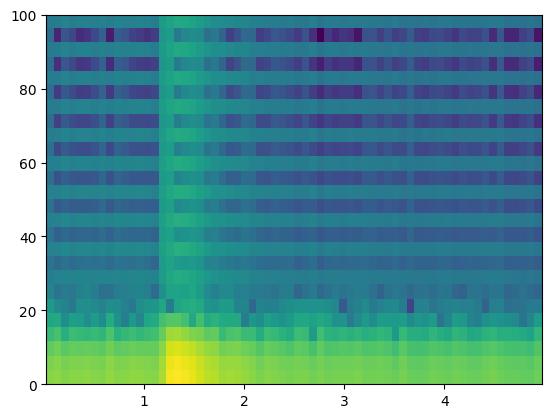

In [9]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np
import json
import os
from sklearn.model_selection import train_test_split

# Initialize lists to store data for all users
# all_X_train = []
# all_y_train = []
# all_X_train_prep_only = []
# all_X_train_prep_only_padded = []

all_X_train_check = []
all_y_train_check = []
all_X_train_prep_only_check = []
all_X_train_prep_only_padded_check = []

# Variable to track the maximum length of train_segment_X across all users
max_length_check = 0

# Read and process data for each user
for entry in entries:
    file_selected = os.path.join(folderData, entry, f"{entry}.json")
    print('Number of users in the dataset:', len(entries))
    print('Processing file:', file_selected)

    with open(file_selected) as file:
        # Read user data
        user = json.load(file)
        name_user = user['userInfo']['name']

        # Create a RecognitionModel instance for the current user
        currentUser = RecognitionModel_test('testing', user)

        print('current user is ', currentUser)


        # Preprocess the data for the current user
        train_segment_X_check = currentUser.preProcessingData()
        # X_train_user_check, centers_check = currentUser.featureExtraction(train_segment_X_check)

        if isinstance(train_segment_X_check, list):
            print(f"Length of train_segment_X_check for user {name_user}: {len(train_segment_X_check)}")

            # Find the maximum length of sequences across all users
            max_seq_length_check = max(max_length_check, max(len(seq) for seq in train_segment_X_check))
            max_length_check = max_seq_length_check  # Update the global max length

            # Pad the sequences to the maximum length
            train_segment_X_check = pad_sequences(train_segment_X_check, maxlen=max_length_check, padding='post', dtype='float32')

            print(f"Padded train_segment_X_check shape for user {name_user}: {train_segment_X_check.shape}")
        else:
            print(f"Shape of train_segment_X_check for user {name_user}: {train_segment_X_check.shape}")

        # Extract features and labels
        # y_train_user_check = currentUser.trainSoftmaxNN(X_train_user_check)
        y_train_user_check = currentUser.trainSoftmaxNN()


        if isinstance(y_train_user_check, pd.DataFrame):
            y_train_user_check = y_train_user_check.values  # Convert DataFrame to numpy array
        if isinstance(train_segment_X_check, pd.DataFrame):
            train_segment_X_check = train_segment_X_check.values  # Convert DataFrame to numpy array

        # Append the current user's data to the full dataset lists
        all_y_train_check.append(y_train_user_check)
        all_X_train_prep_only_check.append(train_segment_X_check)

# Now, pad all data to the consistent length
for user_data in all_X_train_prep_only_check:
    # Pad the sequences to the maximum length
    padded_user_data_check = pad_sequences(user_data, maxlen=max_length_check, padding='post', dtype='float32')
    all_X_train_prep_only_padded_check.append(padded_user_data_check)

    # Print the shape of the padded data to verify padding worked
    print(f"Padded data shape for user: {padded_user_data_check.shape}")

# Convert the list of padded arrays into a single numpy array
all_X_train_prep_only_padded_check = np.vstack(all_X_train_prep_only_padded_check)

# Check the shape after padding
print(f"Total padded train_segment_X_check shape: {all_X_train_prep_only_padded_check.shape}")

# Convert lists of arrays to single numpy arrays
all_y_train_check = np.vstack(all_y_train_check)  # Stack arrays vertically

# Ensure that the lengths of all_X_train_prep_only_padded and all_y_train match
if all_X_train_prep_only_padded_check.shape[0] != all_y_train_check.shape[0]:
    print(f"Warning: Mismatch in lengths! X_prep_only: {all_X_train_prep_only_padded_check.shape[0]}, y: {all_y_train_check.shape[0]}")

# Split the padded train_segment_X into training and testing sets
# X_train_split, X_test_split, y_train_split, y_test_split = train_test_split(
#     all_X_train_prep_only_padded,
#     all_y_train,
#     test_size=0.2,
#     random_state=42
# )

# # Verify split shapes
# print(f"X_train_split shape: {X_train_split.shape}, y_train_split shape: {y_train_split.shape}")
# print(f"X_test_split shape: {X_test_split.shape}, y_test_split shape: {y_test_split.shape}")


print(f"all_X_train_prep_only_padded_check shape: {all_X_train_prep_only_padded_check.shape}, all_y_train_check shape: {all_y_train_check.shape}")


# model testing on raw data

### CNN

## Accuracy check for int x trained model with int x test data,

### int x test + fixed point model
### int x test + float point model

In [10]:
print(all_X_train_prep_only_padded_check)

[[[0.02046371 0.0147088  0.00861726 ... 0.00862545 0.00585051 0.00793967]
  [0.01766184 0.01362932 0.00915943 ... 0.00903137 0.01060633 0.00792714]
  [0.01509894 0.01257701 0.00964767 ... 0.00936253 0.01507085 0.00789884]
  ...
  [0.         0.         0.         ... 0.         0.         0.        ]
  [0.         0.         0.         ... 0.         0.         0.        ]
  [0.         0.         0.         ... 0.         0.         0.        ]]

 [[0.00249228 0.00816997 0.0020895  ... 0.01501918 0.01026069 0.01498815]
  [0.00471091 0.00845781 0.00413662 ... 0.01447274 0.01275231 0.01425988]
  [0.00670133 0.0087285  0.00602397 ... 0.01393852 0.01511876 0.01353157]
  ...
  [0.         0.         0.         ... 0.         0.         0.        ]
  [0.         0.         0.         ... 0.         0.         0.        ]
  [0.         0.         0.         ... 0.         0.         0.        ]]

 [[0.01386922 0.00874989 0.01483506 ... 0.00787327 0.02090801 0.00760918]
  [0.01229371 0.009375

In [11]:
print(all_y_train_check)

[[1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1.

In [12]:
import joblib
# import tensorflow as tf

# 1. Load the saved scaler and PCA model (from your training notebook)
scaler = joblib.load("scaler.pkl")
pca = joblib.load("pca_model.pkl")

# 2. Assume you have your test data ready in variable `all_X_test` with shape (n_samples, time_steps, original_features)
all_X_test_ = all_X_train_prep_only_padded_check
print('all_X_train_prep_only_padded_check_m1_1.shape', all_X_test_.shape)

# Get original shapes
n_samples, time_steps, n_features = all_X_test_.shape  # n_features is 8

# 3. Reshape test data to 2D: (n_samples * time_steps, n_features)
all_X_test_reshaped = all_X_test_.reshape(-1, n_features)
print('all_X_test_reshaped.shape',all_X_test_reshaped.shape)

# 4. Standardize the test data using the loaded scaler
all_X_test_scaled = scaler.transform(all_X_test_reshaped)

# 5. Apply PCA transformation using the loaded PCA model
#    This will reduce the feature dimension from n_features to n_components (e.g., 4, as in training)
all_X_test_pca = pca.transform(all_X_test_scaled)

# 6. Reshape the PCA-transformed data back to 3D: (n_samples, time_steps, n_components)
n_components = all_X_test_pca.shape[1]  # 6 here
all_X_test_pca = all_X_test_pca.reshape(n_samples, time_steps, n_components)
print('all_X_test_pca.shape',all_X_test_pca.shape)

all_X_train_prep_only_padded_check_m1_1.shape (150, 999, 8)
all_X_test_reshaped.shape (149850, 8)
all_X_test_pca.shape (150, 999, 6)


/usr/local/lib/python3.11/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.5.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator PCA from version 1.5.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [13]:
print(all_X_test_pca)

[[[-4.89062399e-01 -5.95631786e-02 -1.84314027e-02  3.41910720e-01
    1.76408261e-01  1.79968122e-02]
  [-5.05446553e-01 -1.06505707e-01  2.21847873e-02  2.56649315e-01
    1.35372356e-01  1.36506092e-02]
  [-5.20484507e-01 -1.49816126e-01  5.97262569e-02  1.78395703e-01
    9.58634615e-02  1.01958560e-02]
  ...
  [-1.06454051e+00 -6.73823729e-02 -1.65429991e-02  5.08912951e-02
   -1.43055664e-02 -1.90916681e-03]
  [-1.06454051e+00 -6.73823729e-02 -1.65429991e-02  5.08912951e-02
   -1.43055664e-02 -1.90916681e-03]
  [-1.06454051e+00 -6.73823729e-02 -1.65429991e-02  5.08912951e-02
   -1.43055664e-02 -1.90916681e-03]]

 [[-6.94874823e-01 -2.84052461e-01  1.72337487e-01  2.31109131e-02
    1.30871207e-01 -6.73255250e-02]
  [-6.48703456e-01 -2.73092687e-01  1.66885823e-01  2.70009730e-02
    1.07232504e-01 -4.51821946e-02]
  [-6.06512010e-01 -2.62637317e-01  1.62273929e-01  3.03637981e-02
    8.47739801e-02 -2.50309855e-02]
  ...
  [-1.06454051e+00 -6.73823729e-02 -1.65429991e-02  5.08912

In [14]:
scale_factor = 100
all_X_test_pca_s = np.round(all_X_test_pca * scale_factor).astype(np.int32)

In [15]:
print(all_X_test_pca_s)

[[[ -49   -6   -2   34   18    2]
  [ -51  -11    2   26   14    1]
  [ -52  -15    6   18   10    1]
  ...
  [-106   -7   -2    5   -1    0]
  [-106   -7   -2    5   -1    0]
  [-106   -7   -2    5   -1    0]]

 [[ -69  -28   17    2   13   -7]
  [ -65  -27   17    3   11   -5]
  [ -61  -26   16    3    8   -3]
  ...
  [-106   -7   -2    5   -1    0]
  [-106   -7   -2    5   -1    0]
  [-106   -7   -2    5   -1    0]]

 [[ -53  -16    9    7   -2    3]
  [ -56  -15    7    5    0    3]
  [ -60  -14    6    3    1    2]
  ...
  [ -51  -31   -9   14   -3  -29]
  [-106   -7   -2    5   -1    0]
  [-106   -7   -2    5   -1    0]]

 ...

 [[ -38    8   21   -9   -7    2]
  [ -39    8   21   -5   -7    1]
  [ -40    8   21   -2   -7    0]
  ...
  [-106   -7   -2    5   -1    0]
  [-106   -7   -2    5   -1    0]
  [-106   -7   -2    5   -1    0]]

 [[ -30  -16   19    7   13    1]
  [ -29  -16   20    7   17    1]
  [ -31  -16   20    9   21    1]
  ...
  [-106   -7   -2    5   -1    0]
  [-

In [16]:
# For your array with shape (3150, 1015, 6), to get (3150, 1019, 6):
print("before Padding shape of all_X_test_pca_s:", all_X_test_pca_s.shape)

before Padding shape of all_X_test_pca_s: (150, 999, 6)


In [17]:

# pad_width = ((0, 0), (0, 4), (0, 0))
pad_width = ((0, 0), (0, 20), (0, 0))

all_X_test_pca_s_padded = np.pad(all_X_test_pca_s, pad_width=pad_width, mode='constant', constant_values=0)
print("Padded shape of all_X_test_pca_s_padded:", all_X_test_pca_s_padded.shape)


Padded shape of all_X_test_pca_s_padded: (150, 1019, 6)


In [18]:
import numpy as np

# Prevent truncation by setting the print threshold to infinity
np.set_printoptions(threshold=np.inf)

print(all_X_test_pca_s_padded)


[[[ -49   -6   -2   34   18    2]
  [ -51  -11    2   26   14    1]
  [ -52  -15    6   18   10    1]
  [ -53  -19    9   11    6    1]
  [ -54  -22   12    5    2    1]
  [ -55  -25   14    1   -1    1]
  [ -55  -27   16   -3   -3    1]
  [ -56  -28   17   -5   -6    1]
  [ -55  -29   18   -5   -8    2]
  [ -55  -29   18   -5   -9    2]
  [ -55  -29   18   -4  -10    2]
  [ -55  -28   17   -3  -11    3]
  [ -55  -27   17   -1  -11    3]
  [ -55  -25   16    1  -11    4]
  [ -56  -24   15    3  -10    4]
  [ -56  -23   15    5   -9    4]
  [ -56  -22   14    6   -8    4]
  [ -57  -21   14    7   -7    4]
  [ -57  -21   15    7   -6    3]
  [ -58  -21   15    7   -4    3]
  [ -58  -21   16    6   -3    3]
  [ -58  -21   16    5   -1    2]
  [ -58  -21   17    4    0    2]
  [ -58  -21   18    4    1    2]
  [ -59  -21   18    3    2    1]
  [ -59  -21   18    2    3    1]
  [ -59  -21   18    2    3    0]
  [ -59  -21   17    2    3    0]
  [ -58  -21   16    2    3    0]
  [ -58  -21  

In [27]:
import numpy as np

# Prevent truncation by setting the print threshold to infinity
np.set_printoptions(threshold=np.inf)

print(all_y_train_check)


[[1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1.

In [19]:
# import tensorflow as tf
import numpy as np

# Define the function to convert floating-point to fixed-point
def float_to_fixed(x, scale_factor=256):
    return (x * scale_factor).round().astype(np.int32)


# Load the original model
model_1d_cnn_relu = keras.saving.load_model('/content/mp_5_a_keras_model.keras')

print('Original model summary is:')
model_1d_cnn_relu.summary()
print('\n')

# Clone the model and copy weights
copied_model_1d_cnn_relu = keras.models.clone_model(model_1d_cnn_relu)
copied_model_1d_cnn_relu.set_weights(model_1d_cnn_relu.get_weights())  # Copy weights and biases from the original model

for original_layer, copied_layer in zip(model_1d_cnn_relu.layers, copied_model_1d_cnn_relu.layers):
    if isinstance(original_layer, (keras.layers.Conv1D, keras.layers.Dense)):
        original_weights, original_biases = original_layer.get_weights()
        copied_weights, copied_biases = copied_layer.get_weights()
        assert np.allclose(original_weights, copied_weights), "Weights mismatch!"
        assert np.allclose(original_biases, copied_biases), "Biases mismatch!"
print("Weights and biases are successfully and correctly copied from original to cloned model without any mismatch!\n")


# Set numpy to print full arrays
np.set_printoptions(threshold=np.inf)  # This will prevent truncation of large arrays

# Open a text file to save the quantized weights and biases
with open('mp_5_a_pca_ori_model_wt_bias.txt', 'w') as f:
    # Iterate over all layers of the model
    # Replace the floating-point weights and biases in the copied model with the quantized ones
    for layer in copied_model_1d_cnn_relu.layers:
        if isinstance(layer, keras.layers.Conv1D) or isinstance(layer, keras.layers.Dense):
            weights, biases = layer.get_weights()
            quantized_weights_1d_cnn_relu = float_to_fixed(weights)
            quantized_biases_1d_cnn_relu = float_to_fixed(biases)
            layer.set_weights([quantized_weights_1d_cnn_relu, quantized_biases_1d_cnn_relu])


            # Write the quantized weights and biases to the text file
            f.write(f"Layer: {layer.name}\n")
            f.write("Quantized Weights:\n")
            f.write(np.array2string(quantized_weights_1d_cnn_relu, separator=', ') + '\n')
            f.write("Quantized Biases:\n")
            f.write(np.array2string(quantized_biases_1d_cnn_relu, separator=', ') + '\n')
            f.write("\n" + "-"*50 + "\n")

print('\n quantized weights and biases are')
print(quantized_weights_1d_cnn_relu)
print(quantized_biases_1d_cnn_relu)
print('\n')

# Compile the model (required for evaluation)
copied_model_1d_cnn_relu.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# # Reshape the input data to match the model's input shape
# all_X_train_check_reshaped_2d = all_X_train_check.reshape((all_X_train_check.shape[0], 2, 3, 1))

# Evaluate the copied model with quantized weights
# loss_check_1d_cnn_relu, accuracy_check_1d_cnn_relu = copied_model_1d_cnn_relu.evaluate(all_X_train_check.reshape((all_X_train_check.shape[0], all_X_train_check.shape[1], 1)), all_y_train_check, verbose=1)

# loss_check_1d_cnn_relu, accuracy_check_1d_cnn_relu = copied_model_1d_cnn_relu.evaluate(all_X_train_check_s_1.reshape((all_X_train_check_s_1.shape[0], all_X_train_check_s_1.shape[1], 1)), all_y_train_check, verbose=1)

# loss_check_1d_cnn_relu, accuracy_check_1d_cnn_relu = copied_model_1d_cnn_relu.evaluate(all_X_train_prep_only_padded_check_m1_1, all_y_train_check, verbose=1)

loss_check_1d_cnn_relu, accuracy_check_1d_cnn_relu = copied_model_1d_cnn_relu.evaluate(all_X_test_pca_s_padded, all_y_train_check, verbose=1)


# Print the test accuracy
print("Test Accuracy:", accuracy_check_1d_cnn_relu)


Original model summary is:


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_8 (Conv1D)               │ (None, 1018, 32)       │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_8 (MaxPooling1D)  │ (None, 509, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_9 (Conv1D)               │ (None, 508, 64)        │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_4      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,380 (106.96 KB)

 Trainable params: 9,126 (35.65 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 18,254 (71.31 KB)



Weights and biases are successfully and correctly copied from original to cloned model without any mismatch!


 quantized weights and biases are
[[ -43 -116    3  -55  -10   47]
 [  -3  -47  -53  -68   27   29]
 [  62   29  -14   27   56    2]
 [   7  -39   24   16 -122   19]
 [  62   49  -79   15  -57   51]
 [ -53  -23  -47  -30  -29    2]
 [ -86  -52  -26   -4   -6   83]
 [  42  -16   -3   73  -36  -20]
 [   8   -4  -17   50  -20  -60]
 [   8  -32   30   71  -24    7]
 [ -63   64  -47   22   36   39]
 [  69   45   47   -7  -78   18]
 [  -3   12   68  -63   19   16]
 [  47   64  -23 -108  -58   18]
 [ -59   62   54   20   19   76]
 [  54  -39  -57  -42  -62   65]
 [  90    8  -49   39  -74   32]
 [   3   45  -21   48  -12  -33]
 [ -31   63  -26  -77  -48  -38]
 [ -67  -29   41   44  -22   48]
 [  13  -33  -50  -56  -13   65]
 [ -87  -26  -67  -63  -10  -37]
 [  79  -31  -68  -24   76  -49]
 [  27  -16  -94  -92  -53   24]
 [  41  -65  -57   28  -36   64]
 [   2   47   62    4   -4  

In [20]:
print(all_X_test_pca_s_padded.shape)

(150, 1019, 6)


In [21]:
print(len(all_X_test_pca_s_padded.shape))

3


In [22]:
# import tensorflow as tf

# Load the saved CNN model.
model_2_1d = keras.saving.load_model('/content/mp_5_a_keras_model.keras')

# Check if the test data is 2D. If it is, add a channel dimension.
if len(all_X_test_pca_s_padded.shape) == 2:
    X_test_eval = all_X_test_pca_s_padded.reshape(
        (all_X_test_pca_s_padded.shape[0],
         all_X_test_pca_s_padded.shape[1], 1)
    )
else:
    X_test_eval = all_X_test_pca_s_padded

# Evaluate the model on the test data.
loss_check_2_1d, accuracy_check_2_1d = model_2_1d.evaluate(
    X_test_eval, all_y_train_check, verbose=1
)

print("Test Accuracy:", accuracy_check_2_1d)


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9605 - loss: 0.1006
Test Accuracy: 0.8933333158493042


### for checking purpose printing int x test

In [ ]:
# print(all_X_train_prep_only_padded_check_m1_1)

In [ ]:
# print(all_y_train_check)

# conf mat

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Confusion Matrix:
[[25  0  0  0  0  0]
 [ 0 25  0  0  0  0]
 [ 0  0 23  2  0  0]
 [ 0  0  0 25  0  0]
 [ 0  0  0 13 11  1]
 [ 0  0  0  0  0 25]]


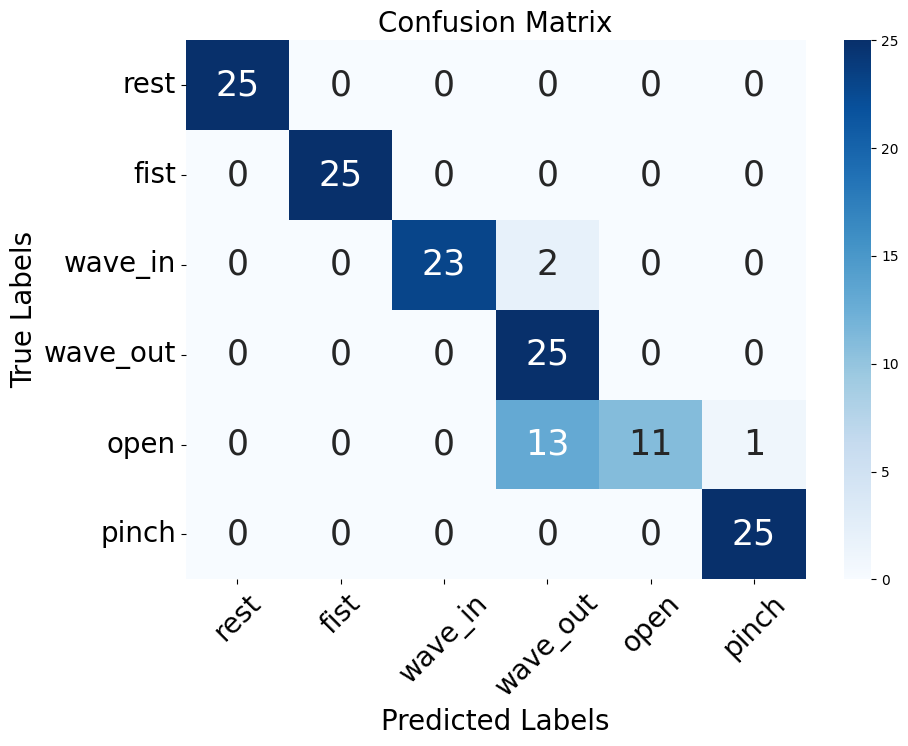


Classification Report:
              precision    recall  f1-score   support

        rest       1.00      1.00      1.00        25
        fist       1.00      1.00      1.00        25
     wave_in       1.00      0.92      0.96        25
    wave_out       0.62      1.00      0.77        25
        open       1.00      0.44      0.61        25
       pinch       0.96      1.00      0.98        25

    accuracy                           0.89       150
   macro avg       0.93      0.89      0.89       150
weighted avg       0.93      0.89      0.89       150



In [23]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

label_names = ["rest", "fist", "wave_in", "wave_out", "open", "pinch"]

# Get predictions for the test set
# y_pred = model_3_tanh.predict(X_test_split.reshape((X_test_split.shape[0], X_test_split.shape[1], 1)))
# y_pred = model_2_1d.predict(all_X_train_check.reshape((all_X_train_check.shape[0], all_X_train_check.shape[1], 1)))

# y_pred = model_2_1d.predict(all_X_train_check_s_1.reshape((all_X_train_check_s_1.shape[0], all_X_train_check_s_1.shape[1], 1)))
y_pred = model_2_1d.predict(all_X_test_pca_s_padded)



y_pred_classes = np.argmax(y_pred, axis=1)  # Get the predicted class indices
y_true = np.argmax(all_y_train_check, axis=1)    # Get the true class indices

# Compute confusion matrix
conf_matrix = confusion_matrix(y_true, y_pred_classes)

# Print the confusion matrix as a raw array
print("Confusion Matrix:")
print(conf_matrix)

# Plot confusion matrix as a heatmap
plt.figure(figsize=(10, 7))
# sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y_true), yticklabels=np.unique(y_true))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names,annot_kws={"size": 25})

plt.title('Confusion Matrix',fontsize=20)
plt.xlabel('Predicted Labels',fontsize=20)
plt.ylabel('True Labels',fontsize=20)

plt.xticks(fontsize=20, rotation=45)  # Increase x-tick labels (class names) size
plt.yticks(fontsize=20, rotation=0)  # Increase y-tick labels (class names) size

plt.show()

# Print classification report
print("\nClassification Report:")
# print(classification_report(y_true, y_pred_classes))
print(classification_report(y_true, y_pred_classes,target_names=label_names))


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Confusion Matrix:
[[25  0  0  0  0  0]
 [ 0 25  0  0  0  0]
 [ 0  0 23  2  0  0]
 [ 0  0  0 25  0  0]
 [ 0  0  0 14 11  0]
 [ 0  0  0  0  0 25]]


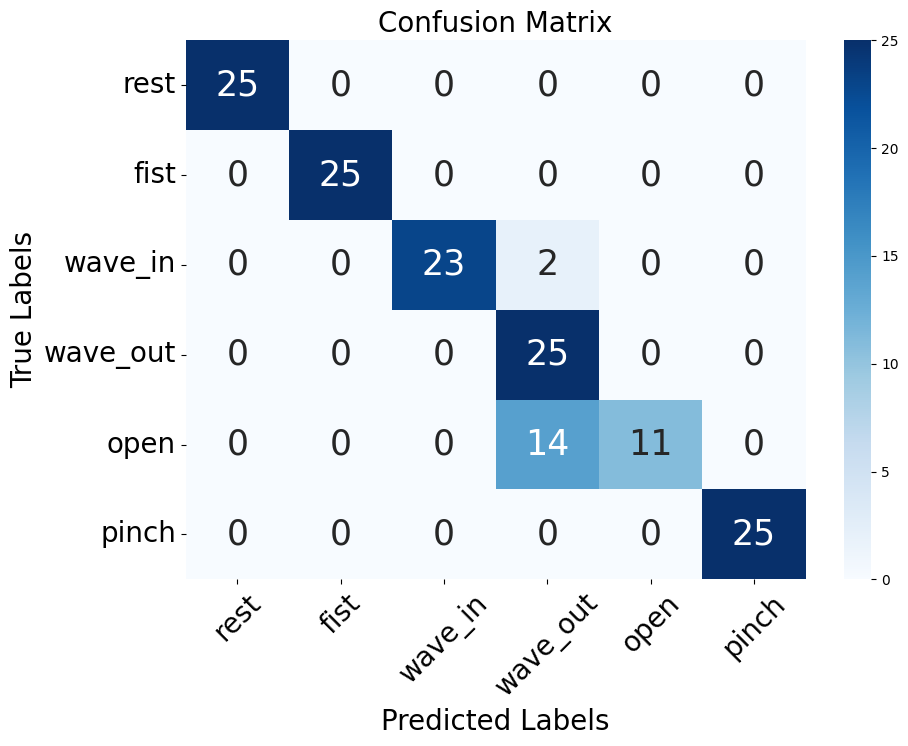


Classification Report:
              precision    recall  f1-score   support

        rest       1.00      1.00      1.00        25
        fist       1.00      1.00      1.00        25
     wave_in       1.00      0.92      0.96        25
    wave_out       0.61      1.00      0.76        25
        open       1.00      0.44      0.61        25
       pinch       1.00      1.00      1.00        25

    accuracy                           0.89       150
   macro avg       0.93      0.89      0.89       150
weighted avg       0.93      0.89      0.89       150



In [24]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

label_names = ["rest", "fist", "wave_in", "wave_out", "open", "pinch"]

# Get predictions for the test set
# y_pred = model_3_tanh.predict(X_test_split.reshape((X_test_split.shape[0], X_test_split.shape[1], 1)))
# y_pred_1 = copied_model_1d_cnn_relu.predict(all_X_train_check.reshape((all_X_train_check.shape[0], all_X_train_check.shape[1], 1)))

# y_pred_1 = copied_model_1d_cnn_relu.predict(all_X_train_check_s_1.reshape((all_X_train_check_s_1.shape[0], all_X_train_check_s_1.shape[1], 1)))

y_pred_1 = copied_model_1d_cnn_relu.predict(all_X_test_pca_s_padded)


y_pred_classes_1 = np.argmax(y_pred_1, axis=1)  # Get the predicted class indices
y_true = np.argmax(all_y_train_check, axis=1)    # Get the true class indices

# Compute confusion matrix
conf_matrix_1 = confusion_matrix(y_true, y_pred_classes_1)

# Print the confusion matrix as a raw array
print("Confusion Matrix:")
print(conf_matrix_1)

# Plot confusion matrix as a heatmap
plt.figure(figsize=(10, 7))
# sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y_true), yticklabels=np.unique(y_true))
sns.heatmap(conf_matrix_1, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names,annot_kws={"size": 25})

plt.title('Confusion Matrix',fontsize=20)
plt.xlabel('Predicted Labels',fontsize=20)
plt.ylabel('True Labels',fontsize=20)

plt.xticks(fontsize=20, rotation=45)  # Increase x-tick labels (class names) size
plt.yticks(fontsize=20, rotation=0)  # Increase y-tick labels (class names) size

plt.show()

# Print classification report
print("\nClassification Report:")
# print(classification_report(y_true, y_pred_classes))
print(classification_report(y_true, y_pred_classes_1,target_names=label_names))



## m_5_a model summary

In [25]:
# import tensorflow as tf

# Load the model from the given path
mdl = keras.saving.load_model('/content/mp_5_a_keras_model.keras')

# Print the model summary
mdl.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_8 (Conv1D)               │ (None, 1018, 32)       │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_8 (MaxPooling1D)  │ (None, 509, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_9 (Conv1D)               │ (None, 508, 64)        │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_4      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,380 (106.96 KB)

 Trainable params: 9,126 (35.65 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 18,254 (71.31 KB)

## shape of weights and biases of the model

In [26]:
# from keras.models import load_model

# Load the model
mdl = keras.saving.load_model('/content/mp_5_a_keras_model.keras')

# Iterate through each layer and print the shapes of weights and biases
for layer in mdl.layers:
    weights = layer.get_weights()  # List containing weights and biases
    if len(weights) > 0:
        print(f"Layer: {layer.name}")
        print(f"  Weights shape: {weights[0].shape}")  # The first element is the weights
        if len(weights) > 1:
            print(f"  Biases shape: {weights[1].shape}")  # The second element is the biases
        print()


Layer: conv1d_8
  Weights shape: (2, 6, 32)
  Biases shape: (32,)

Layer: conv1d_9
  Weights shape: (2, 32, 64)
  Biases shape: (64,)

Layer: dense_8
  Weights shape: (64, 64)
  Biases shape: (64,)

Layer: dense_9
  Weights shape: (64, 6)
  Biases shape: (6,)

